WEEK 4

In [ ]:
#cleaning and preprocessing
import pandas as pd                 # Load dataset (Titanic dataset from seaborn or CSV)
try:
    import seaborn as sns
except ModuleNotFoundError:
    import sys
    !{sys.executable} -m pip install seaborn
    import seaborn as sns
df = sns.load_dataset("titanic")
print("Data shape:", df.shape)
print(df.head())
# Handle missing values
df['age']=df['age'].fillna(df['age'].median())
df['embarked']=df['embarked'].fillna(df['embarked'].mode()[0])
# Drop duplicates
df.drop_duplicates(inplace=True)
# Encode categorical variables
df = pd.get_dummies(df, columns=['sex','class','embarked'], drop_first=True)
# Feature engineering: family size
df['family_size'] = df['sibsp'] + df['parch']
print(df.head())


Data shape: (891, 15)
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
   survived  pclass   age  sibsp  parch     fare    who  adult_male deck  \
0         0       3  22.0      1      0   7.2500    man        True  NaN   
1         1       1  38.0      1      0  71.2

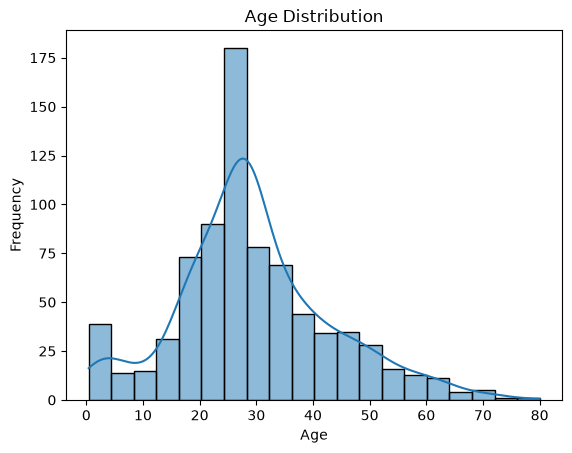

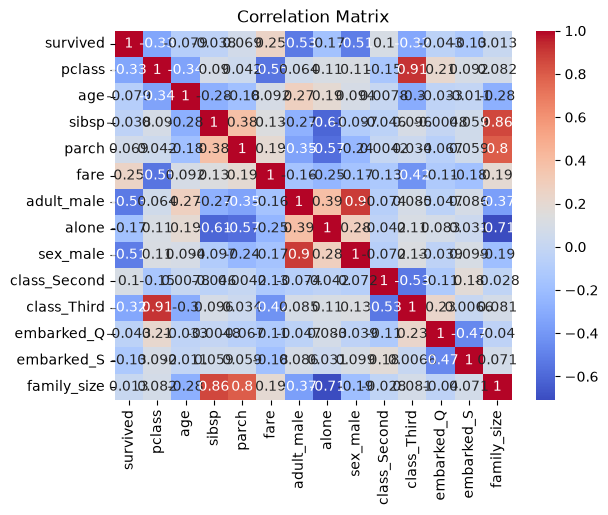

In [3]:
#Exploratory Data Analysis (EDA)
import matplotlib.pyplot as plt
import seaborn as sns

# Histogram of age
sns.histplot(df['age'], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# Correlation matrix
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()


In [ ]:
#data modeling
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression


# Define features and target
X = df.drop(columns=['survived'])
y = df['survived']

# Convert remaining categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True)

# Handle missing values
X = X.fillna(X.median(numeric_only=True))

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [ ]:
#model evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Confusion Matrix:
 [[89  0]
 [ 0 68]]


WEEK 5

In [7]:
#normilazation
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Example dataset
data = pd.DataFrame({
    'A': [10, 20, 30, 40, 50],
    'B': [5, 15, 25, 35, 45]
})

# Apply Min-Max Normalization
scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(data)

# Convert back to DataFrame
normalized_df = pd.DataFrame(normalized_data, columns=data.columns)

print("Normalized Data (MinMaxScaler):")
print(normalized_df)


Normalized Data (MinMaxScaler):
      A     B
0  0.00  0.00
1  0.25  0.25
2  0.50  0.50
3  0.75  0.75
4  1.00  1.00


In [8]:
#standardization
import pandas as pd

from sklearn.preprocessing import StandardScaler
# Example dataset
data = pd.DataFrame({
    'A': [10, 20, 30, 40, 50],
    'B': [5, 15, 25, 35, 45]
})


# Apply Standardization
scaler = StandardScaler()
standardized_data = scaler.fit_transform(data)#fit and transform the data

# Convert back to DataFrame
standardized_df = pd.DataFrame(standardized_data, columns=data.columns)

print("\nStandardized Data (Z-score):")
print(standardized_df)



Standardized Data (Z-score):
          A         B
0 -1.414214 -1.414214
1 -0.707107 -0.707107
2  0.000000  0.000000
3  0.707107  0.707107
4  1.414214  1.414214


In [9]:
#categorical data
df = pd.DataFrame({'Color': ['Red', 'Blue', 'Green', 'Red', 'Blue']})

# One-hot encoding
one_hot = pd.get_dummies(df, columns=['Color'])

print("\nOne-Hot Encoding:")
print(one_hot)



One-Hot Encoding:
   Color_Blue  Color_Green  Color_Red
0       False        False       True
1        True        False      False
2       False         True      False
3       False        False       True
4        True        False      False


In [12]:
#pca
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset
tips = sns.load_dataset("tips")

# Select numeric columns
numeric_cols = tips.select_dtypes(include=['float64','int64'])  # Select only columns whose data type is float64 or int64

# Step 1: Standardize the data (important for PCA)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_cols)
# Step 2: Apply PCA
pca = PCA(n_components=2)   # project data into 2 dimensions
pca_result = pca.fit_transform(scaled_data)
# Step 3: Create a DataFrame with PCA results
pca_df = pd.DataFrame(data=pca_result, columns=['PC1','PC2'])
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("\nPCA Result (first 5 rows):")
print(pca_df.head())



Explained variance ratio: [0.72627656 0.1730423 ]

PCA Result (first 5 rows):
        PC1       PC2
0 -1.348415  0.426746
1 -0.955740  1.093576
2  0.540971  0.122324
3  0.067789 -0.674616
4  1.408308  0.847661


Explained variance ratio: [0.9912126 0.0087874]

LDA Result (first 5 rows):
        LD1       LD2  target
0  8.143648 -0.303471       0
1  7.201062  0.794647       0
2  7.565869  0.268079       0
3  6.882372  0.677440       0
4  8.214873 -0.519686       0


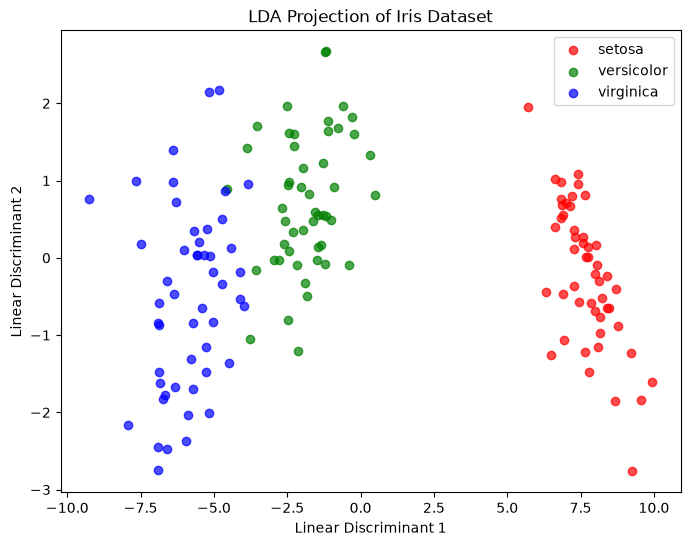

In [13]:
#lda
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import matplotlib.pyplot as plt

# Load dataset
iris = load_iris()
X = iris.data        # features
y = iris.target      # target labels

# Step 1: Apply LDA
lda = LinearDiscriminantAnalysis(n_components=2)  # reduce to 2 dimensions
X_lda = lda.fit_transform(X, y)

# Step 2: Create DataFrame with LDA results
lda_df = pd.DataFrame(X_lda, columns=['LD1', 'LD2'])
lda_df['target'] = y

print("Explained variance ratio:", lda.explained_variance_ratio_)
print("\nLDA Result (first 5 rows):")
print(lda_df.head())

# Step 3: Visualize LDA projection
plt.figure(figsize=(8,6))
for label, color in zip([0,1,2], ['red','green','blue']):
    plt.scatter(
        lda_df.loc[lda_df['target']==label, 'LD1'],
        lda_df.loc[lda_df['target']==label, 'LD2'],
        label=iris.target_names[label],
        color=color,
        alpha=0.7
    )

plt.xlabel('Linear Discriminant 1')
plt.ylabel('Linear Discriminant 2')
plt.title('LDA Projection of Iris Dataset')
plt.legend()
plt.show()


t-SNE Result (first 5 rows):
       TSNE1     TSNE2  target
0 -25.502390 -1.643927       0
1 -23.042055 -0.994582       0
2 -22.787239 -2.096912       0
3 -22.498199 -1.861895       0
4 -25.574633 -2.148222       0


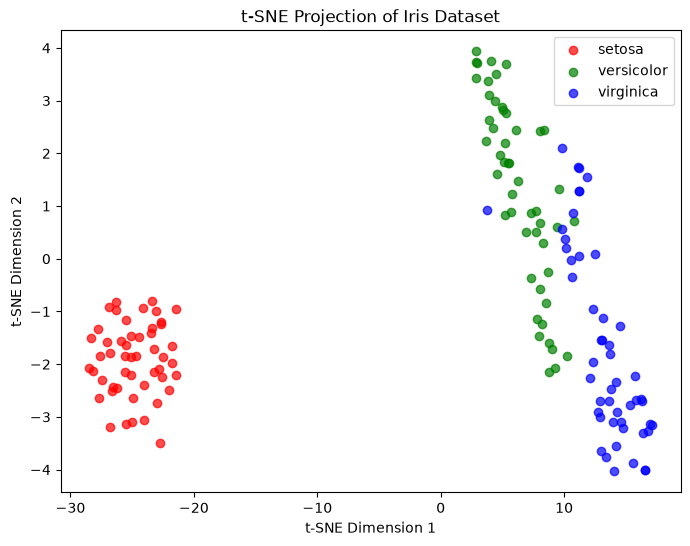

In [14]:
#t-sne
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Load Iris dataset
iris = load_iris()

X = iris.data        # features
y = iris.target      # target labels

# Apply t-SNE
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    max_iter=1000
)

X_tsne = tsne.fit_transform(X)

# Create DataFrame with t-SNE results
tsne_df = pd.DataFrame(
    X_tsne,
    columns=['TSNE1', 'TSNE2']
)

tsne_df['target'] = y

# Display first 5 rows
print("t-SNE Result (first 5 rows):")
print(tsne_df.head())

# Visualize t-SNE projection
plt.figure(figsize=(8, 6))

for label, color in zip(
    [0, 1, 2],
    ['red', 'green', 'blue']
):
    
    plt.scatter(
        tsne_df.loc[tsne_df['target'] == label, 'TSNE1'],
        tsne_df.loc[tsne_df['target'] == label, 'TSNE2'],
        label=iris.target_names[label],
        color=color,
        alpha=0.7
    )

plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.title('t-SNE Projection of Iris Dataset')
plt.legend()
plt.show()


WEEK 6

In [10]:
import pandas as pd
from sklearn.datasets import load_iris
# Load Iris dataset
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
print("First 5 rows of dataset:")
print(df.head())
# Range (max - min)
range_values = df.max() - df.min()
print("\nRange values:")
print(range_values)
# Variance
variance_values = df.var()
print("\nVariance values:")
print(variance_values)
# Standard Deviation
std_values = df.std()
print("\nStandard Deviation values:")
print(std_values)
# Interquartile Range (IQR)
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
print("\nInterquartile Range (IQR):")
print(IQR)


First 5 rows of dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Range values:
sepal length (cm)    3.6
sepal width (cm)     2.4
petal length (cm)    5.9
petal width (cm)     2.4
dtype: float64

Variance values:
sepal length (cm)    0.685694
sepal width (cm)     0.189979
petal length (cm)    3.116278
petal width (cm)     0.581006
dtype: float64

Standard Deviation values:
sepal length (cm)    0.828066
sepal width (cm)     0.435866
petal length (cm)    1.765298
petal width (cm)     0.762238
dtype: float64

Interquartile Range (IQR):
sepal length (cm)    1.3
sepal width (cm)    

In [11]:
import pandas as pd
from sklearn.datasets import load_iris
# Load Iris dataset
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
print("First 5 rows of dataset:")
print(df.head())
# Skewness (asymmetry of distribution)
skewness_values = df.skew()
print("\nSkewness values:")
print(skewness_values)
# Kurtosis (peakedness / tail heaviness)
kurtosis_values = df.kurt()
print("\nKurtosis values:")
print(kurtosis_values)


First 5 rows of dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Skewness values:
sepal length (cm)    0.314911
sepal width (cm)     0.318966
petal length (cm)   -0.274884
petal width (cm)    -0.102967
dtype: float64

Kurtosis values:
sepal length (cm)   -0.552064
sepal width (cm)     0.228249
petal length (cm)   -1.402103
petal width (cm)    -1.340604
dtype: float64


WEEK 7

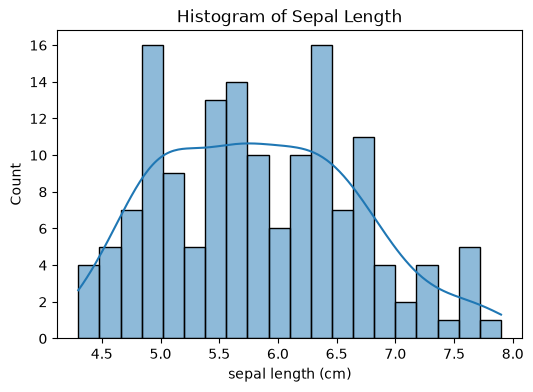

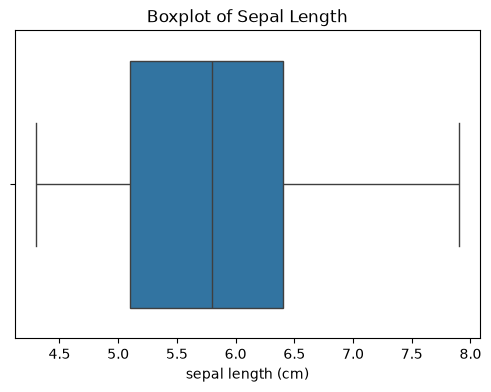

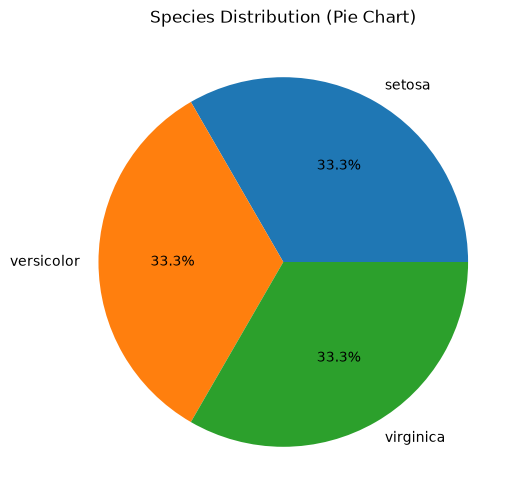

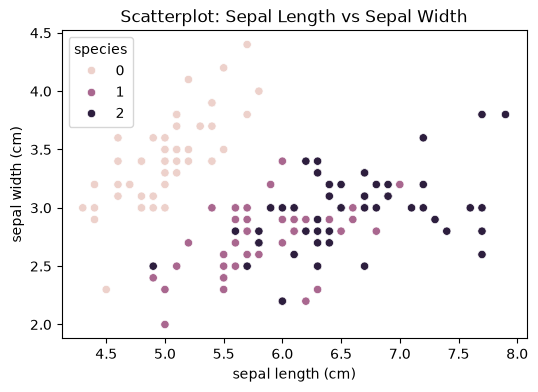

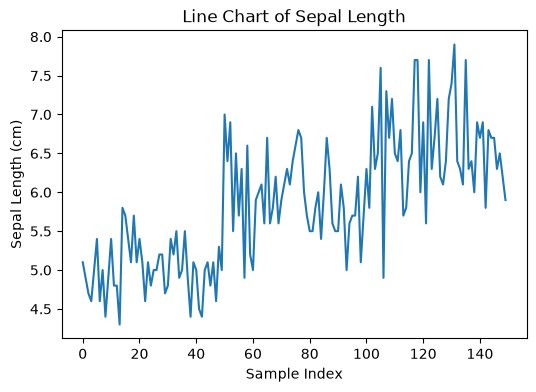

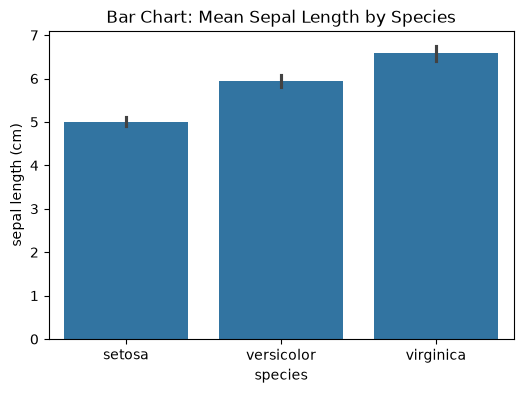

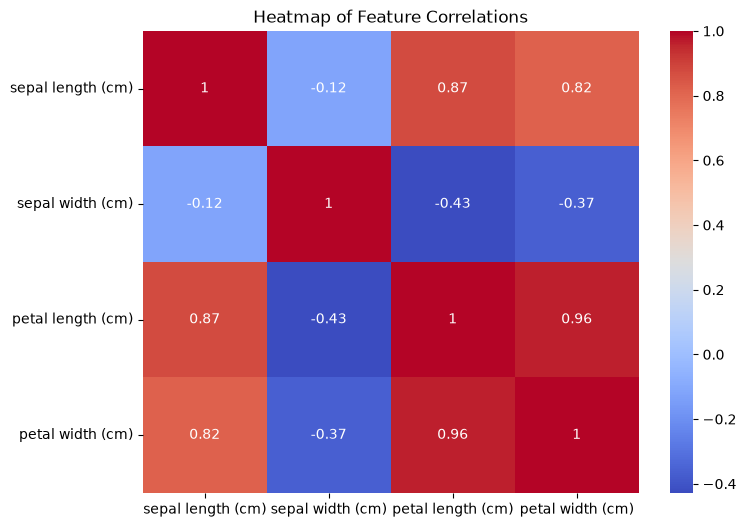

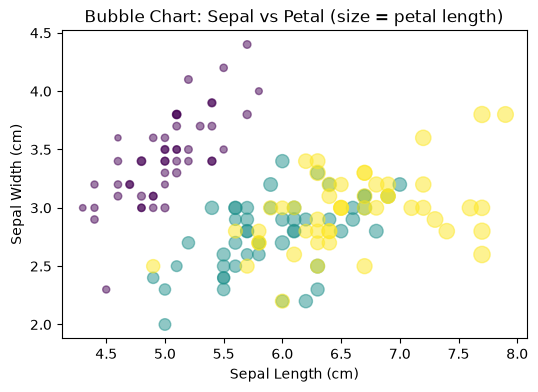

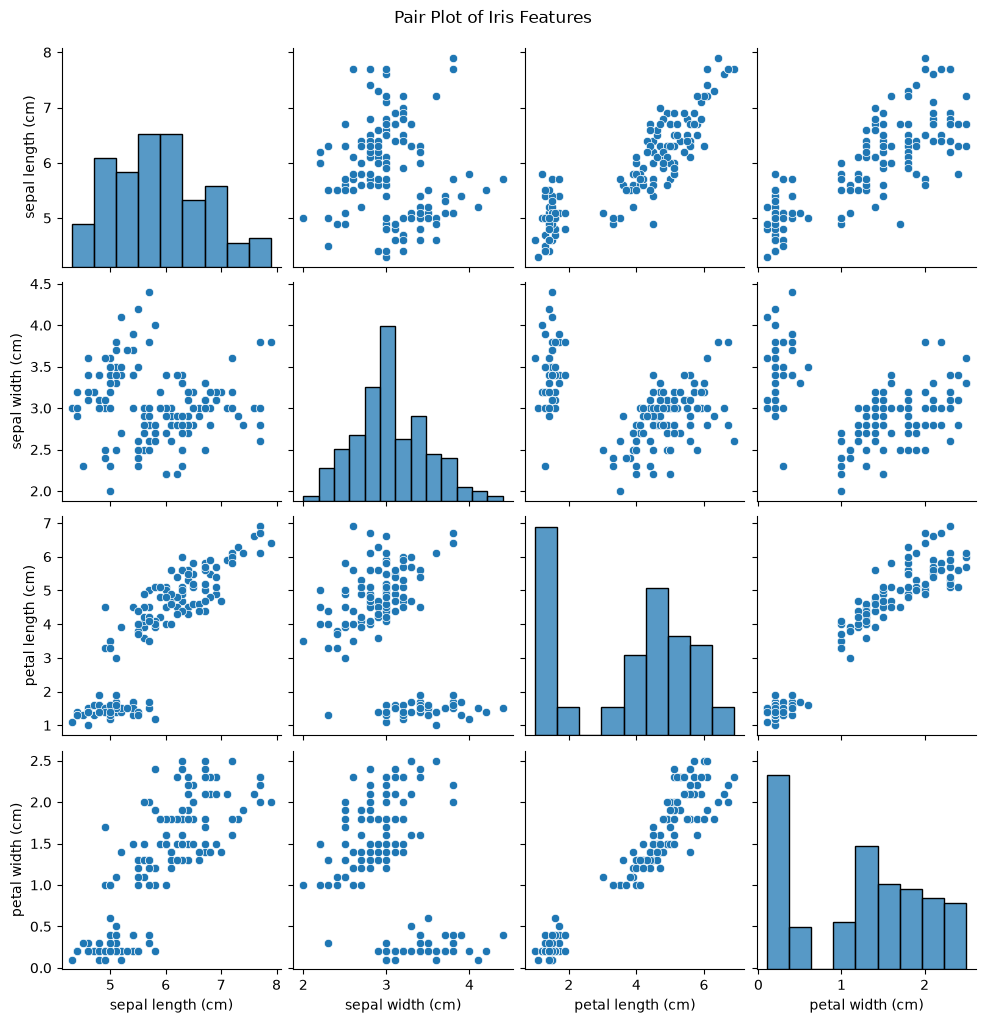

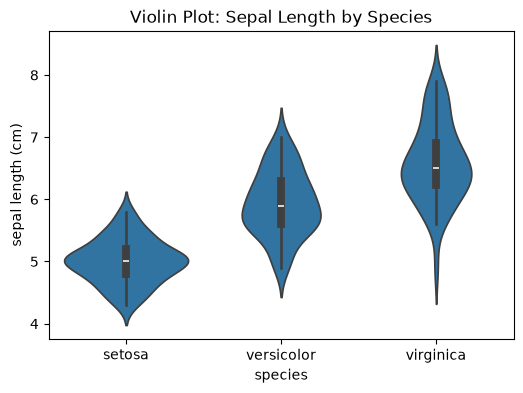

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# Load Iris dataset
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target
# 1. Univariate Visualizations
# Histogram
plt.figure(figsize=(6,4))
sns.histplot(df['sepal length (cm)'], bins=20, kde=True)
plt.title("Histogram of Sepal Length")
plt.show()

# Boxplot
plt.figure(figsize=(6,4))
sns.boxplot(x=df['sepal length (cm)'])
plt.title("Boxplot of Sepal Length")
plt.show()

# Pie Chart (species distribution)
species_counts = df['species'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(species_counts, labels=iris.target_names, autopct='%1.1f%%')
plt.title("Species Distribution (Pie Chart)")
plt.show()

# 2. Bivariate Visualizations

# Scatterplot
plt.figure(figsize=(6,4))
sns.scatterplot(x=df['sepal length (cm)'], y=df['sepal width (cm)'], hue=df['species'])
plt.title("Scatterplot: Sepal Length vs Sepal Width")
plt.show()
# Line Chart (trend of sepal length across samples)
plt.figure(figsize=(6,4))
plt.plot(df['sepal length (cm)'])
plt.title("Line Chart of Sepal Length")
plt.xlabel("Sample Index")
plt.ylabel("Sepal Length (cm)")
plt.show()
# Bar Chart (mean sepal length per species)
plt.figure(figsize=(6,4))
sns.barplot(x=df['species'], y=df['sepal length (cm)'])
plt.title("Bar Chart: Mean Sepal Length by Species")
plt.xticks([0,1,2], iris.target_names)
plt.show()
# 3. Multivariate Visualizations
# Heatmap (correlation matrix)
plt.figure(figsize=(8,6))
sns.heatmap(df.iloc[:,:4].corr(), annot=True, cmap="coolwarm")
plt.title("Heatmap of Feature Correlations")
plt.show()
# Bubble Chart (scatterplot with size = petal length)
plt.figure(figsize=(6,4))
plt.scatter(df['sepal length (cm)'], df['sepal width (cm)'],
            s=df['petal length (cm)']*20, alpha=0.5, c=df['species'])
plt.title("Bubble Chart: Sepal vs Petal (size = petal length)")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.show()
# Pair Plot (relationships among all features)
sns.pairplot(df.iloc[:,:4])
plt.suptitle("Pair Plot of Iris Features", y=1.02)
plt.show()
# 4. Advanced Techniques
# Violin Plot
plt.figure(figsize=(6,4))
sns.violinplot(x=df['species'], y=df['sepal length (cm)'])
plt.title("Violin Plot: Sepal Length by Species")
plt.xticks([0,1,2], iris.target_names)
plt.show()
